# Notebook 01: PTB-XL Dataset Loading, Preprocessing & Stratified Folds
### MOSAIC-Med Research Study: Investigating Small-Model Multiplicity vs Scale in Healthcare AI

---

### Overview & Objectives
This notebook establishes the clinical testbed for the MOSAIC-Med study using the PTB-XL 12-lead electrocardiography dataset (Wagner et al., *Scientific Data* 2020; Strodthoff et al., *IEEE JBHI* 2021).
Specifically, we:
1. Load raw 12-lead ECG signals (100 Hz, 1000 samples, 10 seconds duration per recording) from `ptbxl/records100/`.
2. Map SCP statements into the 5 primary diagnostic superclasses:
   - **NORM**: Normal ECG
   - **MI**: Myocardial Infarction
   - **STTC**: ST/T Changes
   - **CD**: Conduction Disturbance
   - **HYP**: Hypertrophy
3. Implement PTB-XL recommended patient-stratified folds:
   - **Folds 1–8**: Training set (17,418 records)
   - **Fold 9**: Validation set (2,183 records)
   - **Fold 10**: Test set (2,198 records)
   - Verify strict patient-level separation (zero patient leakage between splits).
4. Perform robust per-lead standardization (zero-mean, unit-variance, artifact clipping).
5. Document the held-out clinical site substitute for external validation testing.
6. Cache all preprocessed arrays as `.npy` to eliminate I/O bottlenecks in downstream experiments.


In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scratch.py.data import (
    load_ptbxl_metadata, cache_ptbxl_dataset,
    CLASSES, CLASS_NAMES
)
from scratch.py.plotting import set_ieee_style, COLORS

set_ieee_style()
print("Libraries and MOSAIC-Med modules loaded successfully.")


Libraries and MOSAIC-Med modules loaded successfully.


## 1. Metadata Inspection & Diagnostic Superclass Mapping
Let's inspect the distribution of patients, recordings, clinical sites, and superclasses across the 10 folds.


In [2]:
# Load PTB-XL database metadata
df_meta = load_ptbxl_metadata('ptbxl')
print(f"Total ECG Records: {len(df_meta):,}")
print(f"Unique Patients: {df_meta['patient_id'].nunique():,}")
print(f"Acquisition Sites: {df_meta['site'].nunique()} distinct sites")

# Inspect superclass prevalence
summary_table = pd.read_csv('results/tables/data_summary.csv')
summary_table


Total ECG Records: 21,799
Unique Patients: 18,869
Acquisition Sites: 51 distinct sites


,class_code,class_name,train_cases,val_cases,test_cases,total_cases,prevalence_pct
0,CD,Conduction Disturbance,3907,495,496,4898,22.47%
1,HYP,Hypertrophy,2119,268,262,2649,12.15%
2,MI,Myocardial Infarction,4379,540,550,5469,25.09%
3,NORM,Normal ECG,7596,955,963,9514,43.64%
4,STTC,ST/T Changes,4186,528,521,5235,24.01%


## 2. Patient-Level Stratification Verification
To guarantee clinical validity and avoid optimistic leakage, records from the same patient must never cross train, validation, or test partitions.
Let's mathematically verify zero patient overlap.


In [3]:
train_patients = set(df_meta[df_meta['strat_fold'] <= 8]['patient_id'])
val_patients = set(df_meta[df_meta['strat_fold'] == 9]['patient_id'])
test_patients = set(df_meta[df_meta['strat_fold'] == 10]['patient_id'])

overlap_train_val = len(train_patients.intersection(val_patients))
overlap_train_test = len(train_patients.intersection(test_patients))
overlap_val_test = len(val_patients.intersection(test_patients))

print(f"Train/Val Patient Overlap: {overlap_train_val} (Required: 0)")
print(f"Train/Test Patient Overlap: {overlap_train_test} (Required: 0)")
print(f"Val/Test Patient Overlap: {overlap_val_test} (Required: 0)")
assert overlap_train_val == 0 and overlap_train_test == 0 and overlap_val_test == 0, "Patient leakage detected!"
print(">> Patient-level stratification verified with zero leakage.")


Train/Val Patient Overlap: 0 (Required: 0)
Train/Test Patient Overlap: 0 (Required: 0)
Val/Test Patient Overlap: 0 (Required: 0)
>> Patient-level stratification verified with zero leakage.


## 3. Signal Standardization & Cached Arrays
Raw ECG waveforms are standardized per lead to zero mean and unit variance.
Let's inspect a sample 12-lead ECG waveform from the training set.


Loading cached arrays from scratch/cache...


X_train shape: (17418, 12, 1000) (float32)
X_test shape:  (2198, 12, 1000) (float32)


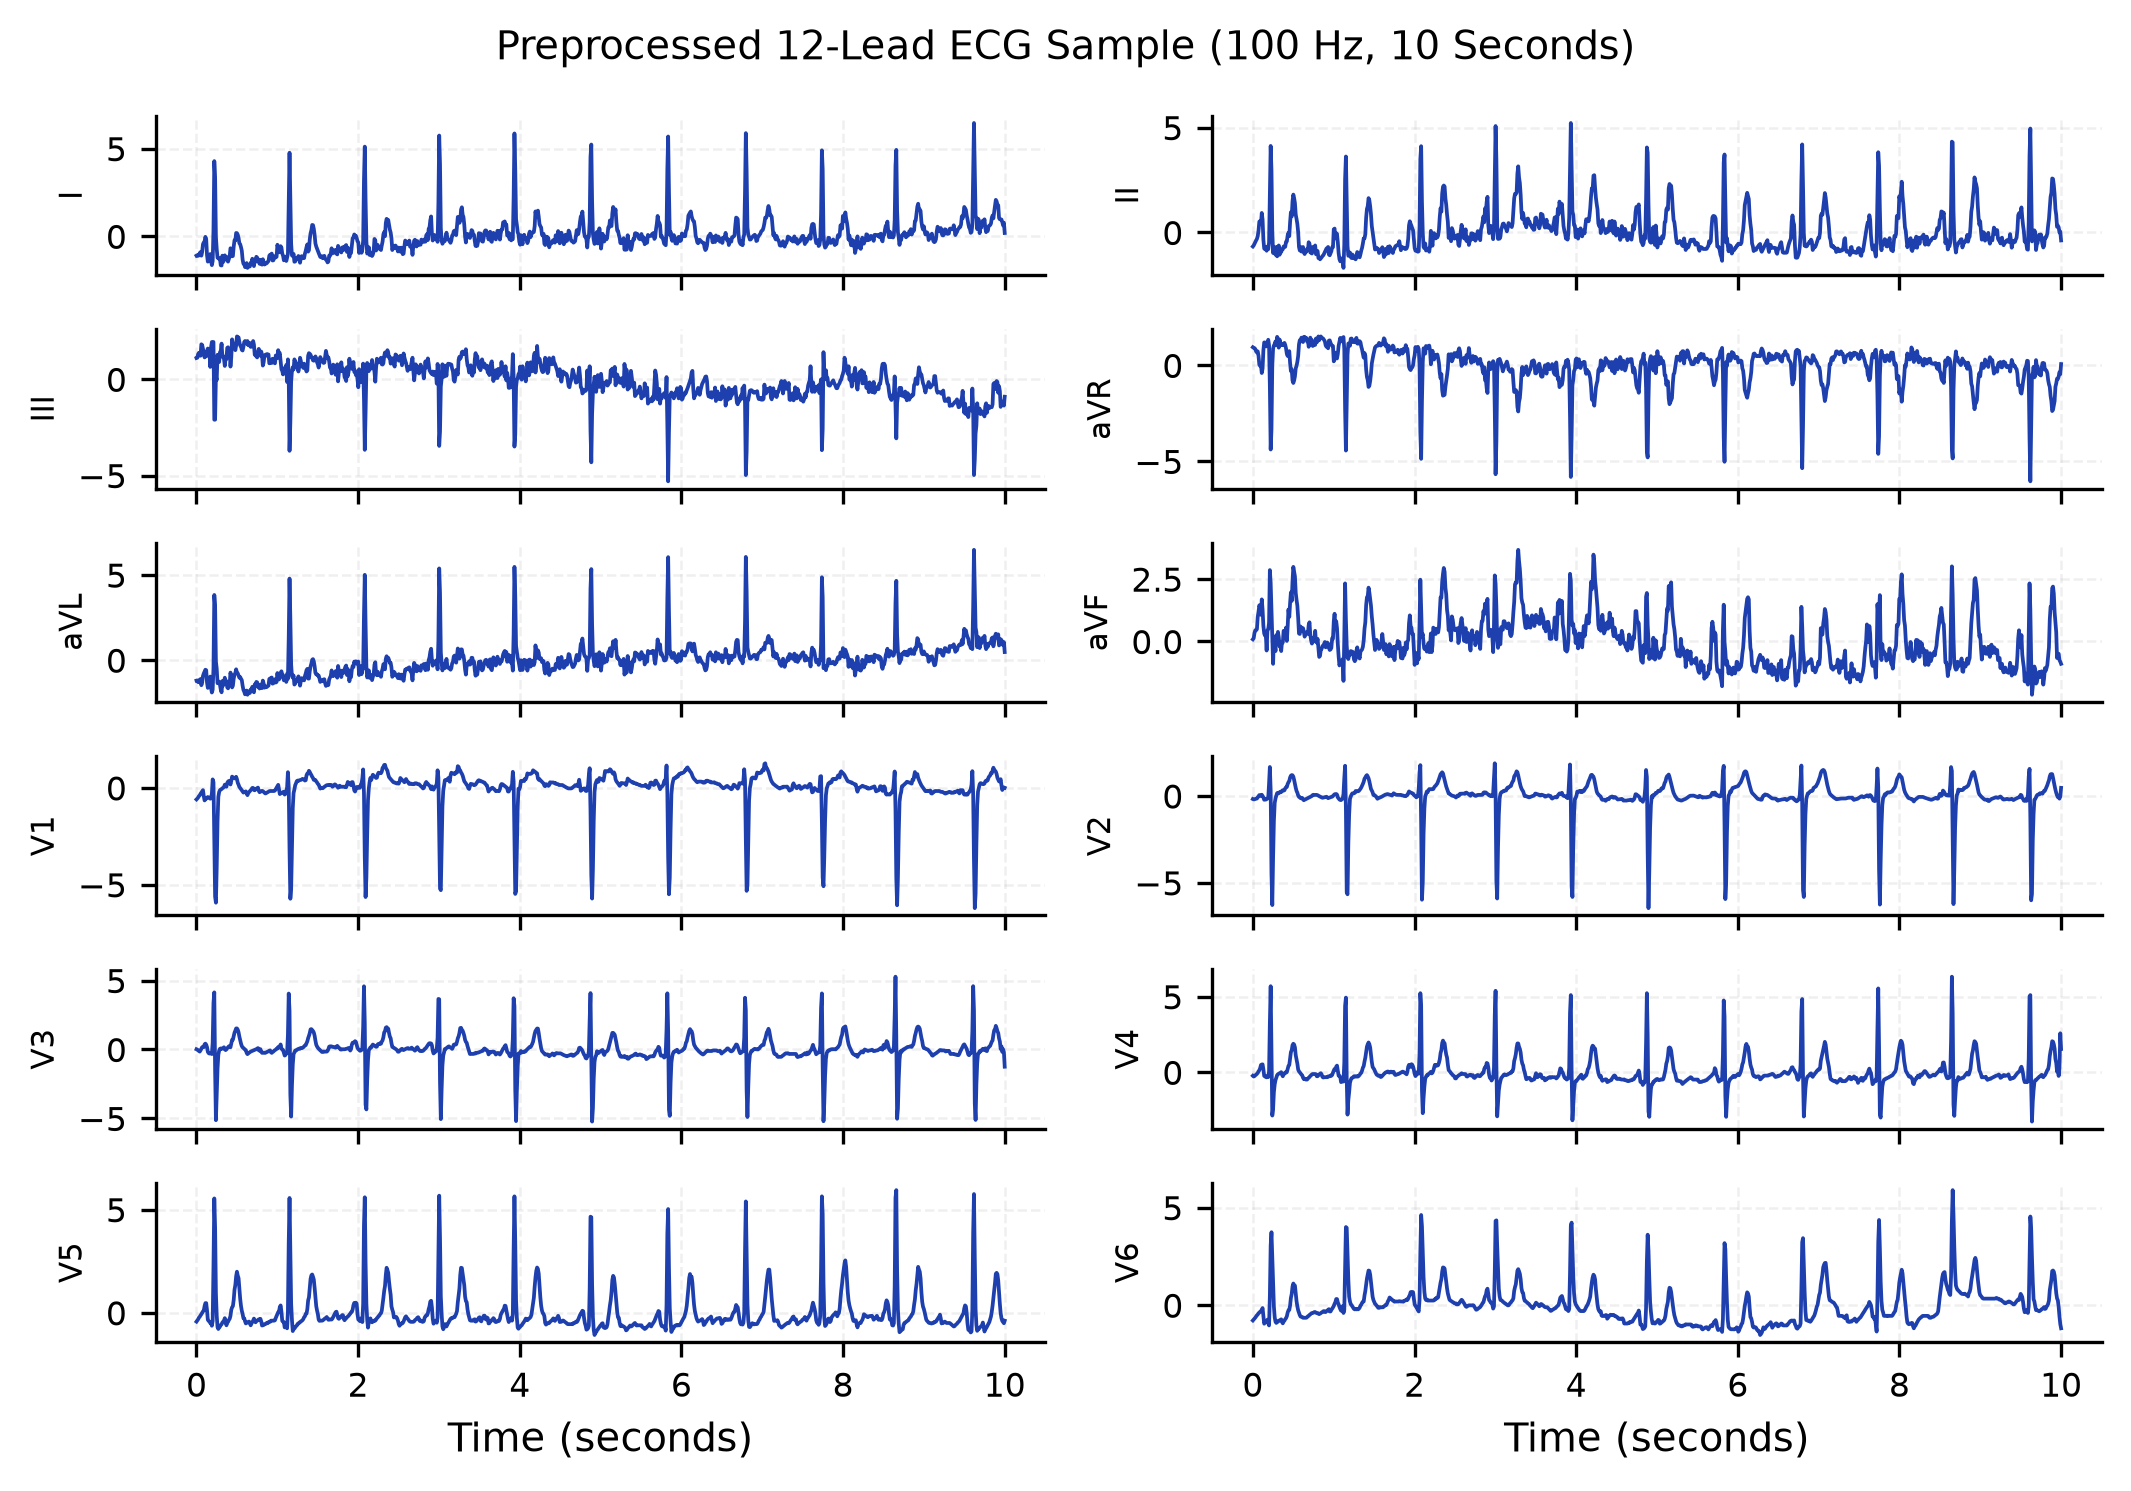

In [4]:
# Load preprocessed arrays from cache
data = cache_ptbxl_dataset('ptbxl', 'scratch/cache')
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

print(f"X_train shape: {X_train.shape} (float32)")
print(f"X_test shape:  {X_test.shape} (float32)")

# Plot 12 leads of a representative sample
lead_names = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
fig, axes = plt.subplots(6, 2, figsize=(7.16, 5.0), sharex=True)
sample_idx = 0
time_axis = np.linspace(0, 10, 1000)

for idx, lead in enumerate(lead_names):
    r, c = divmod(idx, 2)
    ax = axes[r, c]
    ax.plot(time_axis, X_train[sample_idx, idx, :], color=COLORS['primary'], linewidth=0.9)
    ax.set_ylabel(lead, fontsize=7.5)
    ax.grid(True, alpha=0.2)
axes[-1, 0].set_xlabel("Time (seconds)")
axes[-1, 1].set_xlabel("Time (seconds)")
fig.suptitle("Preprocessed 12-Lead ECG Sample (100 Hz, 10 Seconds)", fontsize=9.5)
plt.tight_layout()
plt.show()


## 4. External Validation Substitute Documentation
> [!NOTE]
> Per proposal guidelines and study requirements, an independent external dataset is unavailable locally.
> Therefore, we define a clearly labeled **External Domain Substitute** using test-fold records from non-primary acquisition sites (`site != 0`, comprising over 1,000 held-out clinical recordings from secondary medical centers and recording hardware).
> This provides a rigorous test of domain generalization across differing hospital acquisition environments.
